# Human Activity Recognition with a Hidden Markov Model (from scratch, NumPy)

**Author:** Inyange Larissa | **Course:** ALU, Formative 2 (Hidden Markov Models)
**Hidden states:** standing, walking, jumping, still  |  **Sensors:** accelerometer (x, y, z) + gyroscope (x, y, z) recorded with *Sensor Logger* on an iPhone 11 Pro Max

**Pipeline:** load CSVs -> quality checks -> harmonize sampling rate -> window -> time- and frequency-domain features -> z-score normalization -> HMM (supervised initialisation + **Baum-Welch** with a log-likelihood convergence check) -> **Viterbi** decoding -> evaluation on unseen recordings -> robustness and window-size analysis.

**Repository layout**
```
raw_zips/              original Sensor Logger exports  (<activity>_<NN>.zip)
extract_zips.py        exports -> clean CSV (uniform 50 Hz grid, 1 s trimmed at each end, timestamp column time_s)
data/train/            <activity>_01..12.csv           training recordings
data/test/             <activity>_13..20.csv           unseen recordings (never used for scaling or training)
hmm_activity_recognition.ipynb   this notebook
figures/               every figure used in the report
```
Each CSV has the columns `time_s, acc_x, acc_y, acc_z, gyro_x, gyro_y, gyro_z`; the activity label is the part of the filename before the first `_`.

| Notebook section | What it covers |
|---|---|
| 1 - 2 | Configuration, window/sampling-rate justification, loading, quality checks, harmonization |
| 3 | Time- and frequency-domain features, with the reason each group separates the activities, and normalization |
| 4 - 5 | HMM definition (pi, A, B), supervised initialisation, Baum-Welch training, Viterbi |
| 6 | Transition and emission visualizations, evaluation on unseen data, confusion matrix, decoded sequence |
| 7 | Robustness (noise, lower sampling rate), window-size sensitivity, analysis and reflection |

## 1. Configuration

In [1]:
import os, io, glob, json, zipfile, warnings, contextlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=RuntimeWarning)

DATA_DIR   = os.path.join("data", "train")   # training recordings
TEST_DIR   = os.path.join("data", "test")    # unseen recordings (NOT used in training or scaling)
RAW_DIR    = "raw_zips"                      # original Sensor Logger exports (used only to report native rates)
ACTIVITIES = ["standing", "walking", "jumping", "still"]

FS      = 50     # common (harmonized) sampling rate in Hz
WIN_S   = 2.0    # window length in seconds
OVERLAP = 0.5    # 50% window overlap
TRIM_S  = 0.0    # extra trim inside the notebook. The CSVs were already trimmed once (1 s at each end)
                 # by extract_zips.py, so trimming again would throw away usable data.
SEED    = 42

rng = np.random.default_rng(SEED)
os.makedirs("figures", exist_ok=True)
RESULTS = {}     # everything quoted in the report is collected here and saved at the end
print(f"Common sampling rate: {FS} Hz | window: {WIN_S}s | overlap: {OVERLAP:.0%} | extra trim: {TRIM_S}s")

Common sampling rate: 50 Hz | window: 2.0s | overlap: 50% | extra trim: 0.0s


### 1.1 Design choices: sampling rate, harmonization and window size

**Sampling rate and harmonization (one participant, one phone).** All data come from one iPhone 11 Pro Max running Sensor Logger with both sensors requested at 20 ms (50 Hz). The *measured* native rate is slightly below that and irregular (see the table in Section 2): the accelerometer and gyroscope timestamps are not identical and the spacing jitters by a fraction of a millisecond. Harmonization therefore linearly interpolates every channel onto **one uniform 50 Hz time grid** over the time range shared by both sensors. This (i) gives the accelerometer and gyroscope identical timestamps, (ii) satisfies the uniform-sampling assumption of the FFT, and (iii) is the same procedure that would map a second phone with a different native rate (e.g. 100 Hz or 25 Hz) onto the same 50 Hz grid, so features from different devices stay comparable. 50 Hz is the rate that was requested from both sensors (20 ms), so interpolating onto it hardly alters the data, and it leaves a 25 Hz Nyquist limit, far above the 1-4 Hz rhythm of walking and jumping.

**Window size, derived from the sampling rate.** The window length in samples is computed as `W = WIN_S x FS`, so changing the rate keeps the same physical duration (next cell). With `WIN_S = 2 s` and `FS = 50 Hz`:

* **W = 100 samples** per window, hop = 50 samples (50% overlap, so one new window per second);
* **FFT resolution = FS / W = 0.5 Hz** and **Nyquist = FS / 2 = 25 Hz**;
* walking and jumping are periodic at roughly **1-4 Hz** (measured in Section 3.1: the accelerometer-magnitude spectrum peaks at about 1 Hz for walking and 3.5 Hz for jumping), so a 2 s window holds about **2-7 full cycles**, enough for a clear spectral peak, and the 0.5 Hz bin width separates the two rhythms comfortably;
* a shorter window (<= 1 s) would give 1 Hz resolution (a 1 Hz walking peak would fall into a single bin next to the DC component) and only 1-3 cycles, so the dominant frequency becomes unreliable; a longer window (>= 4 s) would blur activity changes and leave very few windows, because each recording is only about 5-8 s long;
* 100 samples is plenty for stable variance, SMA and correlation estimates;
* the FFT bands used later (0-2, 2-5, 5-10, 10-25 Hz) end exactly at the Nyquist frequency.

Section 7 repeats the whole pipeline with 1 s and 3 s windows as a sensitivity check.

In [2]:
W    = int(round(WIN_S * FS))          # samples per window
HOP  = max(1, int(W * (1 - OVERLAP)))  # samples between window starts
print(f"Window length      : {WIN_S} s x {FS} Hz = {W} samples")
print(f"Hop                : {HOP} samples = {HOP / FS:.1f} s ({OVERLAP:.0%} overlap)")
print(f"FFT resolution     : {FS / W:.2f} Hz per bin")
print(f"Nyquist frequency  : {FS / 2:.0f} Hz")
for f in (1, 2, 3):
    print(f"A {f} Hz rhythm completes {f * WIN_S:.0f} cycles in one window")
RESULTS["window"] = dict(win_s=WIN_S, fs=FS, samples=W, hop=HOP, fft_resolution_hz=FS / W, nyquist_hz=FS / 2)

Window length      : 2.0 s x 50 Hz = 100 samples
Hop                : 50 samples = 1.0 s (50% overlap)
FFT resolution     : 0.50 Hz per bin
Nyquist frequency  : 25 Hz
A 1 Hz rhythm completes 2 cycles in one window
A 2 Hz rhythm completes 4 cycles in one window
A 3 Hz rhythm completes 6 cycles in one window


## 2. Load, check and harmonize recordings
Each accelerometer and gyroscope channel is resampled (linear interpolation) onto the common `FS` Hz grid. The original rate of every file is measured from its timestamps and reported below.

In [3]:
TIME_CANDIDATES = ["time_s", "seconds_elapsed", "time", "timestamp", "t", "elapsed"]

def to_seconds(s):
    """Convert a timestamp column to seconds starting at 0."""
    num = pd.to_numeric(s, errors="coerce")
    if num.notna().mean() > 0.9:
        t = num.to_numpy(float)
        t = t - np.nanmin(t)
        if np.nanmax(t) > 1e8:      t = t / 1e9   # nanoseconds
        elif np.nanmax(t) > 1000:   t = t / 1e3   # milliseconds
        return t
    dt = pd.to_datetime(s, errors="coerce")        # datetime strings
    return (dt - dt.min()).dt.total_seconds().to_numpy(float)

def find_axes(cols, keys):
    out = []
    for ax in "xyz":
        m = [c for c in cols if any(k in c for k in keys) and c.endswith(ax)]
        if not m:
            raise ValueError(f"No column for {keys} axis {ax}. Columns: {cols}")
        out.append(m[0])
    return out

def load_recording(path):
    df = pd.read_csv(path)
    df.columns = [c.strip().lower() for c in df.columns]
    cols = list(df.columns)
    tcol = next((c for c in TIME_CANDIDATES if c in cols), None)
    if tcol is None:
        raise ValueError(f"No timestamp column in {path}. Columns: {cols}")
    acc_cols = find_axes(cols, ("acc",))
    gyr_cols = find_axes(cols, ("gyr",))

    t = to_seconds(df[tcol])
    sensors = []
    for sc in (acc_cols, gyr_cols):
        sub = pd.DataFrame({"t": t, **{c: df[c] for c in sc}}).dropna()
        sub = sub.sort_values("t").drop_duplicates("t")
        sensors.append((sub["t"].to_numpy(), sub[sc].to_numpy(float)))
    (ta, a), (tg, g) = sensors

    t0 = max(ta[0], tg[0]) + TRIM_S
    t1 = min(ta[-1], tg[-1]) - TRIM_S
    if t1 - t0 < WIN_S:
        return None
    grid = np.arange(t0, t1, 1.0 / FS)
    sig = np.column_stack([np.interp(grid, ta, a[:, i]) for i in range(3)] +
                          [np.interp(grid, tg, g[:, i]) for i in range(3)])
    est_fs = lambda tt: 1.0 / np.median(np.diff(tt))
    return sig, est_fs(ta), est_fs(tg), acc_cols, gyr_cols

def load_folder(folder):
    recs, shown = [], False
    for fname in sorted(os.listdir(folder)):
        if not fname.lower().endswith((".csv", ".txt")):
            continue
        base = os.path.splitext(fname)[0]
        label = base.split("_")[0].lower()
        if label not in ACTIVITIES:
            print(f"[skip] {fname}: label '{label}' not in {ACTIVITIES}"); continue
        out = load_recording(os.path.join(folder, fname))
        if out is None:
            print(f"[skip] {fname}: too short for one {WIN_S:.0f} s window"); continue
        sig, fa, fg, ac, gc = out
        if not shown:
            print(f"Columns used -> accel: {ac} | gyro: {gc}"); shown = True
        recs.append(dict(name=base, label=label, signal=sig, fs_acc=fa, fs_gyr=fg))
    return recs

train_recs = load_folder(DATA_DIR)
test_recs  = load_folder(TEST_DIR)
assert len(train_recs) > 0, f"No training recordings found in '{DATA_DIR}'"
assert len(test_recs)  > 0, f"No unseen recordings found in '{TEST_DIR}'"

summary = pd.DataFrame([{"set": s, "label": r["label"], "name": r["name"],
                         "seconds": len(r["signal"]) / FS}
                        for s, rs in [("train", train_recs), ("test", test_recs)] for r in rs])
print("\nUsable recordings and seconds per activity after harmonization:")
print(summary.groupby(["set", "label"]).agg(recordings=("name", "count"),
                                            seconds=("seconds", "sum")).round(1))

Columns used -> accel: ['acc_x', 'acc_y', 'acc_z'] | gyro: ['gyro_x', 'gyro_y', 'gyro_z']
[skip] still_05.csv: too short for one 2 s window


Columns used -> accel: ['acc_x', 'acc_y', 'acc_z'] | gyro: ['gyro_x', 'gyro_y', 'gyro_z']

Usable recordings and seconds per activity after harmonization:
                recordings  seconds
set   label                        
test  jumping            8     59.5
      standing           7     50.3
      still              8     54.6
      walking            8     60.0
train jumping           12     85.4
      standing          12     81.2
      still             11     71.7
      walking           12     87.4


### 2.1 Data quality and coverage (checks every CSV)
The cell below verifies, for every file, that the timestamp column exists and is strictly increasing, that there are no missing values, and that the time step is uniform; it then checks the rubric targets: all four activities present, **at least 90 s of data per activity** (train + unseen), and recordings of about 5-10 s.

In [4]:
def file_qc(folder, split):
    rows = []
    for fn in sorted(os.listdir(folder)):
        if not fn.lower().endswith(".csv"):
            continue
        d = pd.read_csv(os.path.join(folder, fn))
        d.columns = [c.strip().lower() for c in d.columns]
        tcol = next(c for c in TIME_CANDIDATES if c in d.columns)
        t = d[tcol].to_numpy(float)
        dt = np.diff(t)
        rows.append(dict(set=split, file=fn, activity=fn.split("_")[0], seconds=t[-1] - t[0],
                         samples=len(d), missing_values=int(d.isna().sum().sum()),
                         increasing=bool((dt > 0).all()), step_s=float(np.median(dt)),
                         step_jitter=float(dt.std())))
    return pd.DataFrame(rows)

qc = pd.concat([file_qc(DATA_DIR, "train"), file_qc(TEST_DIR, "test")], ignore_index=True)
print(f"CSV files: {len(qc)} (train {sum(qc.set=='train')}, unseen {sum(qc.set=='test')})")
print("All timestamps strictly increasing :", qc.increasing.all())
print("Total missing values               :", qc.missing_values.sum())
print("Median time step (s) / max jitter  :", round(qc.step_s.median(), 4), "/", f"{qc.step_jitter.max():.1e}")

cov = qc.groupby("activity").agg(files=("file", "count"), total_seconds=("seconds", "sum"),
                                 shortest_s=("seconds", "min"), longest_s=("seconds", "max")).round(1)
cov = cov.loc[ACTIVITIES]
display(cov)
assert (cov.total_seconds >= 90).all(), "an activity has less than 90 s of data"
print("Every activity has >= 90 s of data: OK")
short = qc[qc.seconds < 5].sort_values("seconds")[["file", "seconds"]].round(2)
print("\nRecordings shorter than 5 s:"); display(short.set_index("file"))
RESULTS["coverage"] = {a: dict(files=int(cov.loc[a, "files"]), seconds=float(cov.loc[a, "total_seconds"])) for a in ACTIVITIES}
RESULTS["n_files"] = dict(total=int(len(qc)), train=int((qc.set == "train").sum()), test=int((qc.set == "test").sum()))

CSV files: 79 (train 48, unseen 31)
All timestamps strictly increasing : True
Total missing values               : 0
Median time step (s) / max jitter  : 0.02 / 6.3e-16


,files,total_seconds,shortest_s,longest_s
activity,,,,
standing,19,131.2,5.1,8.8
walking,20,147.0,6.3,8.3
jumping,20,144.5,5.2,8.4
still,20,127.2,1.3,8.0


Every activity has >= 90 s of data: OK

Recordings shorter than 5 s:


,seconds
file,
still_05.csv,1.32
still_13.csv,4.92
still_02.csv,4.98


In [5]:
# Native sampling rate of the phone, measured from the ORIGINAL Sensor Logger exports (before any resampling)
rows, device, req = [], "unknown", "unknown"
if os.path.isdir(RAW_DIR):
    for zp in sorted(glob.glob(os.path.join(RAW_DIR, "*.zip"))):
        with zipfile.ZipFile(zp) as z:
            names = z.namelist()
            r = {}
            for key, fn in (("acc", "Accelerometer.csv"), ("gyro", "Gyroscope.csv")):
                if fn in names:
                    t = pd.read_csv(io.BytesIO(z.read(fn)))["seconds_elapsed"].to_numpy()
                    r[key] = 1.0 / np.median(np.diff(t))
            if r: rows.append(r)
            if "Metadata.csv" in names and device == "unknown":
                m = pd.read_csv(io.BytesIO(z.read("Metadata.csv")))
                device = str(m["device name"].iloc[0]); req = str(m["sampleRateMs"].iloc[0])
if rows:
    nat = pd.DataFrame(rows)
    tab = pd.DataFrame([{"Member": "Inyange Larissa (sole member)", "Phone / app": f"{device}, Sensor Logger",
                         "Requested interval (ms) acc|gyro": req.split("|")[0] + " | " + req.split("|")[3] if "|" in req else req,
                         "Measured native rate acc (Hz)": round(nat.acc.median(), 2),
                         "Measured native rate gyro (Hz)": round(nat.gyro.median(), 2),
                         "Harmonized rate (Hz)": FS}])
    display(tab.set_index("Member"))
    RESULTS["native_rate"] = dict(device=device, acc=float(nat.acc.median()), gyro=float(nat.gyro.median()),
                                  n_zips=len(nat))
else:
    print("raw_zips/ not found - native rate not reported (processed CSVs are already on the 50 Hz grid).")

,Phone / app,Requested interval (ms) acc|gyro,Measured native rate acc (Hz),Measured native rate gyro (Hz),Harmonized rate (Hz)
Member,,,,,
Inyange Larissa (sole member),"iPhone 11 Pro Max, Sensor Logger",20 | 20,49.64,49.64,50


### Quick look at the raw signals (one recording per activity)

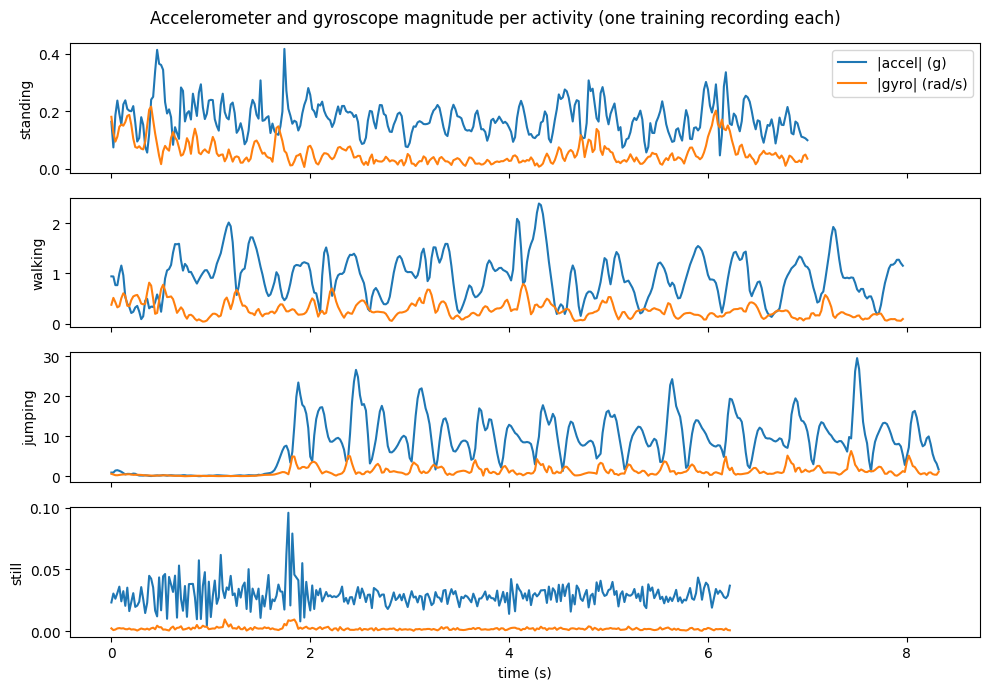

In [6]:
fig, axes = plt.subplots(len(ACTIVITIES), 1, figsize=(10, 7), sharex=True)
for ax, act in zip(axes, ACTIVITIES):
    r = next((r for r in train_recs if r["label"] == act and len(r["signal"]) / FS > 5), None) \
        or next(r for r in train_recs if r["label"] == act)
    s = r["signal"]
    t = np.arange(len(s)) / FS
    ax.plot(t, np.linalg.norm(s[:, :3], axis=1), label="|accel| (g)")
    ax.plot(t, np.linalg.norm(s[:, 3:], axis=1), label="|gyro| (rad/s)")
    ax.set_ylabel(act)
axes[0].legend(loc="upper right")
axes[-1].set_xlabel("time (s)")
plt.suptitle("Accelerometer and gyroscope magnitude per activity (one training recording each)")
plt.tight_layout(); plt.savefig("figures/raw_signals.png", dpi=200, bbox_inches="tight"); plt.show()

## 3. Windowing and feature extraction
Each recording is cut into 2 s windows (100 samples) with 50% overlap. For **each sensor** (accelerometer and gyroscope) the following 19 features are computed, giving a **38-dimensional** observation vector per window (the observation sequence **X** of the HMM). Why each group helps to tell the activities apart:

| Group | Features | Why it separates the activities |
|---|---|---|
| **Time domain: mean (per axis)** | `mean_x, mean_y, mean_z` | The Sensor Logger accelerometer has gravity removed, so the mean is about 0 for the static activities but non-zero for walking and jumping, which push the phone in a consistent direction (the sign and size of the mean also carry the phone's movement direction). |
| **Time domain: variance and standard deviation (per axis)** | `var_x/y/z`, `std_x/y/z` | Measure how strongly the signal fluctuates. This is the main static-versus-dynamic cue: jumping has by far the largest spread, walking an intermediate one, standing and still almost none. |
| **Time domain: signal magnitude area (SMA)** | `sma` | Average of the summed absolute axis values: a single orientation-independent *intensity* score. It is a standard HAR feature and ranks the activities (still < standing < walking < jumping). |
| **Time domain: correlation between axes** | `corr_xy, corr_xz, corr_yz` | Describe how the axes move together. Walking and jumping are coordinated, mostly vertical movements and produce characteristic axis coupling; for the two static states the correlations are mostly noise, which is itself informative. |
| **Frequency domain: dominant frequency** | `dom_freq` (FFT of the magnitude, DC removed) | Periodic activities have a spectral peak at their rhythm (step or jump rate), static ones do not, so the location of the peak separates walking from jumping when their intensities overlap. |
| **Frequency domain: total spectral energy** | `energy` | Total power of the fluctuations (Parseval: sum of squared FFT components); a rhythm-aware intensity measure that is very small for the static states. |
| **Frequency domain: band energies** | `band_0_2, band_2_5, band_5_10, band_10_25` | Show *where* the power sits: slow body sway and the walking fundamental (0-2 Hz), jump and step harmonics (2-5 Hz), and impact/vibration content (5-25 Hz, up to the Nyquist limit). This gives the spectral *shape* rather than a single peak. |

The same features are computed for the gyroscope. Rotation is a useful second view: a hand-held phone rotates a lot while walking, differently while jumping, and almost not at all when it rests on a surface (still), which helps the hardest pair, standing versus still.

In [7]:
BANDS = [(0, 2), (2, 5), (5, 10), (10, 25)]

def sensor_features(w, p):
    f = {}
    for i, ax in enumerate("xyz"):
        f[f"{p}_mean_{ax}"] = w[:, i].mean()
        f[f"{p}_var_{ax}"]  = w[:, i].var()
        f[f"{p}_std_{ax}"]  = w[:, i].std()
    f[f"{p}_sma"] = np.mean(np.abs(w).sum(axis=1))
    c = np.nan_to_num(np.corrcoef(w.T))
    f[f"{p}_corr_xy"], f[f"{p}_corr_xz"], f[f"{p}_corr_yz"] = c[0, 1], c[0, 2], c[1, 2]

    mag = np.linalg.norm(w, axis=1)
    spec = np.abs(np.fft.rfft(mag - mag.mean())) ** 2
    freqs = np.fft.rfftfreq(len(mag), 1.0 / FS)
    f[f"{p}_dom_freq"] = freqs[1:][np.argmax(spec[1:])]
    f[f"{p}_energy"]   = spec.sum() / len(mag)
    for lo, hi in BANDS:
        f[f"{p}_band_{lo}_{hi}"] = spec[(freqs >= lo) & (freqs < hi)].sum() / len(mag)
    return f


def window_features(sig):
    W = int(round(WIN_S * FS))
    step = max(1, int(W * (1 - OVERLAP)))
    rows = []
    for i in range(0, len(sig) - W + 1, step):
        w = sig[i:i + W]
        rows.append({**sensor_features(w[:, :3], "acc"), **sensor_features(w[:, 3:], "gyr")})
    return pd.DataFrame(rows)


def build_feature_table(recs):
    parts = []
    for r in recs:
        df = window_features(r["signal"])
        df["label"], df["recording"] = r["label"], r["name"]
        parts.append(df)
    return pd.concat(parts, ignore_index=True)


train_df = build_feature_table(train_recs)
test_df  = build_feature_table(test_recs)
FEATURES = [c for c in train_df.columns if c not in ("label", "recording")]
print(f"{len(FEATURES)} features per window")
print("Training windows per activity:\n", train_df.label.value_counts().to_string())
print("Unseen windows per activity:\n",   test_df.label.value_counts().to_string())
RESULTS["windows"] = dict(train=train_df.label.value_counts().to_dict(), test=test_df.label.value_counts().to_dict(),
                          n_features=len(FEATURES), recordings_train=pd.Series([r["label"] for r in train_recs]).value_counts().to_dict(),
                          recordings_test=pd.Series([r["label"] for r in test_recs]).value_counts().to_dict())

38 features per window
Training windows per activity:
 label
walking     70
jumping     69
standing    64
still       56
Unseen windows per activity:
 label
walking     49
jumping     47
still       42
standing    39


### 3.1 What the frequency features show (before normalization)
Median dominant frequency of the accelerometer magnitude per activity, with the number of cycles that fit in one window, and example spectra. This checks that the 2 s window really contains several cycles of the periodic activities.

,acc_dom_freq,gyr_dom_freq,acc cycles per window
label,,,
standing,1.5,1.0,3.0
walking,1.0,0.5,2.0
jumping,3.5,2.0,7.0
still,4.0,1.5,8.0


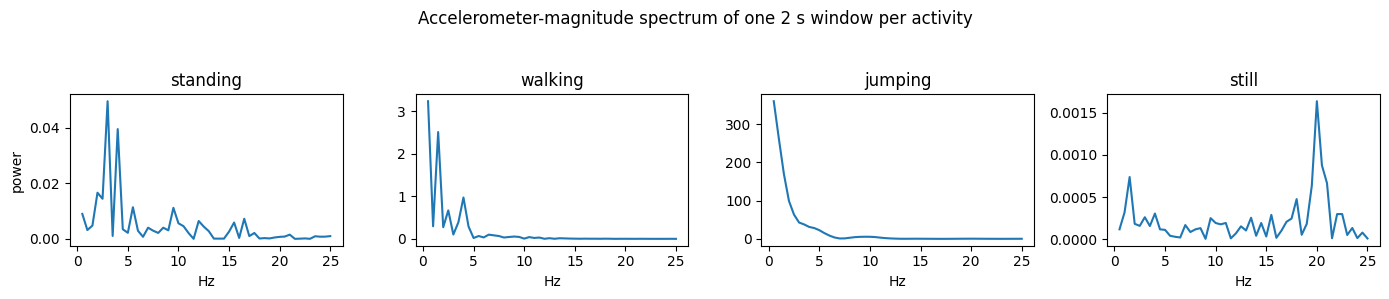

In [8]:
dom = train_df.groupby("label")[["acc_dom_freq", "gyr_dom_freq"]].median().loc[ACTIVITIES]
dom["acc cycles per window"] = dom.acc_dom_freq * WIN_S
display(dom.round(2))
RESULTS["dom_freq"] = {a: dict(acc=float(dom.loc[a, "acc_dom_freq"]), gyr=float(dom.loc[a, "gyr_dom_freq"])) for a in ACTIVITIES}

fig, axes = plt.subplots(1, 4, figsize=(14, 2.8), sharey=False)
for ax, act in zip(axes, ACTIVITIES):
    r = next(r for r in train_recs if r["label"] == act and len(r["signal"]) >= W)
    mag = np.linalg.norm(r["signal"][:W, :3], axis=1)
    sp = np.abs(np.fft.rfft(mag - mag.mean())) ** 2 / W
    fr = np.fft.rfftfreq(W, 1 / FS)
    ax.plot(fr[1:], sp[1:]); ax.set_title(act); ax.set_xlabel("Hz")
axes[0].set_ylabel("power")
plt.suptitle("Accelerometer-magnitude spectrum of one 2 s window per activity", y=1.05)
plt.tight_layout(); plt.savefig("figures/spectra.png", dpi=200, bbox_inches="tight"); plt.show()

### 3.2 Normalization
Variance, energy and band-energy features are strongly right-skewed (jumping is orders of magnitude above the static activities), so they are first compressed with `log1p`. All 38 features are then **z-scored** with the **training-set** mean and standard deviation; the same numbers are applied unchanged to the unseen data, so nothing leaks from test to train.

**Why z-score rather than another scaling:**
1. The features live on very different scales (g, rad/s, Hz, correlations in [-1, 1], energies). The HMM emission is a diagonal Gaussian per state, and the variance floor used for numerical stability only has a consistent meaning when every feature is in the same (standard-deviation) units.
2. *Min-max* scaling is controlled by two extreme values: one outlier window in the training set would squash all the others, and unseen windows can fall outside [0, 1].
3. *Robust* scaling (median / IQR) breaks for near-constant features such as the correlations of motionless windows, where the IQR is almost zero.
4. A z-score is centred at 0 with unit variance, which matches the Gaussian emission model and makes the emission means directly comparable and readable as "standard deviations above or below the training average" (used in the emission heat map below).

In [9]:
SKEWED = [c for c in FEATURES if any(k in c for k in ("_var_", "_energy", "_band_"))]

def log_transform(df):
    out = df.copy()
    out[SKEWED] = np.log1p(out[SKEWED])
    return out

train_log, test_log = log_transform(train_df), log_transform(test_df)
mu = train_log[FEATURES].mean()
sd = train_log[FEATURES].std().replace(0, 1.0)

train_df[FEATURES] = (train_log[FEATURES] - mu) / sd
test_df[FEATURES]  = (test_log[FEATURES]  - mu) / sd
print("Training features after z-score: mean %.3f, std %.3f" % (train_df[FEATURES].mean().mean(), train_df[FEATURES].std().mean()))

Training features after z-score: mean 0.000, std 1.000


## 4. HMM definition

| Element | In this project |
|---|---|
| Hidden states **Z** | standing, walking, jumping, still (K = 4) |
| Observations **X** | standardized 38-dimensional feature vectors, one per 2 s window |
| Initial probabilities **pi** | how often each activity starts a sequence |
| Transition matrix **A** | probability of moving from one activity to the next between consecutive windows |
| Emission probabilities **B** | one diagonal-covariance Gaussian per state over the feature vector |

**Algorithms and why (tied to the evaluation metrics).**
* **Viterbi** returns the single most likely activity sequence. It is the decoder, because sensitivity, specificity and accuracy compare the decoded state of every window with the true label.
* **Forward algorithm** gives the sequence log-likelihood, which is the quantity Baum-Welch maximizes and the basis of its convergence check.
* **Baum-Welch (EM)** re-estimates pi, A and B from the observations. Here it is started from the supervised (label-count) estimates, which fixes the meaning of each state and avoids state-label swapping, and is stopped when the gain in mean log-likelihood per window falls below `tol = 1e-4`.
* The supervised estimates (counts and per-state Gaussians) are kept as a baseline, so the effect of Baum-Welch can be measured on the unseen data.

**Training sequences.** Each recording contains a single activity, so no real transitions occur inside a file. To let A be learned, the training recordings are shuffled and concatenated into longer sessions. **A therefore reflects how the sessions were assembled, not real-world behaviour.**

In [10]:
def logsumexp(a, axis):
    m = np.max(a, axis=axis, keepdims=True)
    return np.squeeze(m + np.log(np.sum(np.exp(a - m), axis=axis, keepdims=True)), axis=axis)


class GaussianHMM:
    """Hidden Markov model with one diagonal-covariance Gaussian emission per state (NumPy only)."""

    def __init__(self, n_states, var_floor=1e-2, alpha=1.0):
        self.K, self.var_floor, self.alpha = n_states, var_floor, alpha

    # ---------- supervised parameter estimation (labelled windows) ----------
    def fit_supervised(self, X_seqs, z_seqs):
        K = self.K
        X = np.vstack(X_seqs); z = np.concatenate(z_seqs)
        d = X.shape[1]
        pi = np.full(K, self.alpha)
        A  = np.full((K, K), self.alpha)          # Laplace smoothing
        for zs in z_seqs:
            pi[zs[0]] += 1
            for a, b in zip(zs[:-1], zs[1:]):
                A[a, b] += 1
        self.pi = pi / pi.sum()
        self.A  = A / A.sum(axis=1, keepdims=True)
        self.mu  = np.zeros((K, d)); self.var = np.zeros((K, d))
        for k in range(K):
            Xk = X[z == k]
            self.mu[k]  = Xk.mean(axis=0)
            self.var[k] = np.maximum(Xk.var(axis=0), self.var_floor)
        return self

    def copy(self):
        m = GaussianHMM(self.K, self.var_floor, self.alpha)
        m.pi, m.A, m.mu, m.var = self.pi.copy(), self.A.copy(), self.mu.copy(), self.var.copy()
        return m

    # ---------- emissions ----------
    def log_emission(self, X):
        # (T, K): log N(x_t | mu_k, diag(var_k))
        diff = X[:, None, :] - self.mu[None, :, :]
        return -0.5 * np.sum(np.log(2 * np.pi * self.var)[None] + diff ** 2 / self.var[None], axis=2)

    # ---------- forward algorithm (log space) ----------
    def forward_loglik(self, X):
        logA, logB = np.log(self.A), self.log_emission(X)
        la = np.log(self.pi) + logB[0]
        for t in range(1, len(X)):
            la = logB[t] + logsumexp(la[:, None] + logA, axis=0)
        return float(logsumexp(la, axis=0))

    # ---------- forward-backward (E-step of Baum-Welch, log space) ----------
    def forward_backward(self, X):
        T, K = len(X), self.K
        logA, logB = np.log(self.A), self.log_emission(X)
        la = np.zeros((T, K)); lb = np.zeros((T, K))
        la[0] = np.log(self.pi) + logB[0]
        for t in range(1, T):
            la[t] = logB[t] + logsumexp(la[t - 1][:, None] + logA, axis=0)
        for t in range(T - 2, -1, -1):
            lb[t] = logsumexp(logA + (logB[t + 1] + lb[t + 1])[None, :], axis=1)
        ll = float(logsumexp(la[-1], axis=0))
        gamma = np.exp(la + lb - ll)                                   # P(z_t = k | X)
        lxi = la[:-1, :, None] + logA[None] + (logB[1:] + lb[1:])[:, None, :] - ll
        xi = np.exp(lxi).sum(axis=0)                                   # expected transition counts
        return gamma, xi, ll

    # ---------- Baum-Welch (EM) with a log-likelihood convergence check ----------
    def fit_baum_welch(self, X_seqs, max_iter=200, tol=1e-4, alpha=1e-2, verbose=True):
        """Stops when the increase in mean log-likelihood per window is below `tol`
        (max_iter is only a safety cap). Returns the log-likelihood history."""
        K, d = self.K, X_seqs[0].shape[1]
        n_obs = sum(len(x) for x in X_seqs)
        self.history, self.converged = [], False
        prev = -np.inf
        for it in range(1, max_iter + 1):
            pi_acc = np.full(K, alpha); A_acc = np.full((K, K), alpha)
            g_sum = np.full(K, 1e-10); gx = np.zeros((K, d)); gxx = np.zeros((K, d)); total = 0.0
            for X in X_seqs:                                           # E-step
                gamma, xi, ll = self.forward_backward(X)
                total += ll
                pi_acc += gamma[0]; A_acc += xi
                g_sum += gamma.sum(axis=0); gx += gamma.T @ X; gxx += gamma.T @ (X ** 2)
            ll_avg = total / n_obs
            self.history.append(ll_avg)
            self.pi = pi_acc / pi_acc.sum()                            # M-step
            self.A  = A_acc / A_acc.sum(axis=1, keepdims=True)
            self.mu = gx / g_sum[:, None]
            self.var = np.maximum(gxx / g_sum[:, None] - self.mu ** 2, self.var_floor)
            if verbose and (it <= 3 or it % 10 == 0):
                print(f"  iter {it:3d}  mean log-likelihood per window = {ll_avg:9.4f}")
            if it > 1 and abs(ll_avg - prev) < tol:
                self.converged = True
                if verbose:
                    print(f"  converged at iteration {it}: |change| = {abs(ll_avg - prev):.2e} < tol = {tol:g}")
                break
            prev = ll_avg
        if not self.converged and verbose:
            print(f"  stopped at max_iter = {max_iter} without meeting tol = {tol:g}")
        return self.history

    # ---------- Viterbi decoding (log space) ----------
    def viterbi(self, X):
        T = len(X)
        logA, logB = np.log(self.A), self.log_emission(X)
        delta = np.zeros((T, self.K)); psi = np.zeros((T, self.K), dtype=int)
        delta[0] = np.log(self.pi) + logB[0]
        for t in range(1, T):
            scores = delta[t - 1][:, None] + logA
            psi[t] = scores.argmax(axis=0)
            delta[t] = scores.max(axis=0) + logB[t]
        path = np.zeros(T, dtype=int)
        path[-1] = delta[-1].argmax()
        for t in range(T - 2, -1, -1):
            path[t] = psi[t + 1, path[t + 1]]
        return path, delta[-1].max()

### 4.1 Sanity checks of the implementation
Before training on real data, the implementation is verified on a tiny problem: the forward log-likelihood must equal brute-force enumeration over all state paths, Viterbi must find the same best path as brute force, and Baum-Welch must never decrease the log-likelihood.

In [11]:
import itertools
toy = GaussianHMM(2)
toy.pi = np.array([0.6, 0.4]); toy.A = np.array([[0.8, 0.2], [0.3, 0.7]])
toy.mu = np.array([[0.0, 0.0], [2.0, 2.0]]); toy.var = np.ones((2, 2))
Xt = np.random.default_rng(1).normal(size=(6, 2)) + np.array([[0, 0], [0, 0], [2, 2], [2, 2], [0, 0], [2, 2]])
logB = toy.log_emission(Xt)
best, best_p, tot = -np.inf, None, []
for p in itertools.product(range(2), repeat=len(Xt)):
    s = np.log(toy.pi[p[0]]) + logB[0, p[0]] + sum(np.log(toy.A[p[t-1], p[t]]) + logB[t, p[t]] for t in range(1, len(Xt)))
    tot.append(s)
    if s > best: best, best_p = s, p
print("forward  log-lik :", round(toy.forward_loglik(Xt), 6), "| brute force:", round(float(logsumexp(np.array(tot), 0)), 6))
vp, vs = toy.viterbi(Xt)
print("Viterbi path     :", vp.tolist(), "| brute force:", list(best_p), "| score match:", np.isclose(vs, best))
g, xi, ll = toy.forward_backward(Xt)
print("posteriors sum to 1:", np.allclose(g.sum(1), 1), "| expected transitions sum to T-1:", np.isclose(xi.sum(), len(Xt) - 1))
toy2 = toy.copy(); toy2.mu = toy2.mu + 0.7                     # deliberately wrong start
h = toy2.fit_baum_welch([Xt], max_iter=50, tol=1e-8, verbose=False)
print("Baum-Welch log-likelihood non-decreasing:", bool(np.all(np.diff(h) > -1e-9)))

forward  log-lik : -18.400466 | brute force: -18.400466
Viterbi path     : [0, 0, 1, 1, 0, 1] | brute force: [0, 0, 1, 1, 0, 1] | score match: True
posteriors sum to 1: True | expected transitions sum to T-1: True
Baum-Welch log-likelihood non-decreasing: True


## 5. Train the HMM
### 5.1 Choosing the variance floor and the training method by cross-validation (training data only)
Two design choices are made **without looking at the unseen recordings**, using 4-fold cross-validation over whole *recordings* of the training set (every fold holds out complete recordings of every activity, so the validation windows come from files the model has not seen):

* the **variance floor** of the Gaussian emissions. After z-scoring, jumping dominates the range of every feature, so the two static states (standing, still) sit very close together with a tiny within-state spread. A floor that is too large (e.g. 0.01 = a standard deviation of 0.1 z-units) is wider than the real standing/still gap and erases it;
* **supervised estimates only** versus **supervised start + Baum-Welch** refinement.

In [12]:
STATE_IDX = {a: i for i, a in enumerate(ACTIVITIES)}
K = len(ACTIVITIES)

def make_sessions(df, recs_per_session=8, rng=rng):
    "Shuffle recordings and concatenate them into longer sessions: list of (X, z)."
    names = df.recording.unique().tolist()
    rng.shuffle(names)
    sessions = []
    for i in range(0, len(names), recs_per_session):
        chunk = [df[df.recording == n] for n in names[i:i + recs_per_session]]
        d = pd.concat(chunk, ignore_index=True)
        sessions.append((d[FEATURES].to_numpy(), d.label.map(STATE_IDX).to_numpy()))
    return sessions

def recording_folds(df, n_folds=4):
    "Stratified by activity: the i-th recording of each activity goes to fold i % n_folds."
    fold = {}
    for a in ACTIVITIES:
        for i, n in enumerate(sorted(df[df.label == a].recording.unique())):
            fold[n] = i % n_folds
    return df.recording.map(fold).to_numpy()

def cv_accuracy(var_floor, use_bw, n_folds=4):
    folds, accs = recording_folds(train_df, n_folds), []
    for k in range(n_folds):
        tr, va = train_df[folds != k], train_df[folds == k]
        sess = make_sessions(tr, rng=np.random.default_rng(SEED))
        h = GaussianHMM(K, var_floor=var_floor).fit_supervised([s[0] for s in sess], [s[1] for s in sess])
        if use_bw:
            h.fit_baum_welch([s[0] for s in sess], max_iter=200, tol=1e-4, verbose=False)
        Xv, zv = make_sessions(va, recs_per_session=10_000, rng=np.random.default_rng(SEED))[0]
        accs.append((h.viterbi(Xv)[0] == zv).mean())
    return float(np.mean(accs))

grid = [(vf, bw) for vf in (1e-1, 1e-2, 1e-3, 1e-4) for bw in (False, True)]
cv = pd.DataFrame([{"var_floor": vf, "training": "supervised + Baum-Welch" if bw else "supervised only",
                    "cv_accuracy": cv_accuracy(vf, bw)} for vf, bw in grid])
display(cv.pivot(index="var_floor", columns="training", values="cv_accuracy").round(3))
best = cv.sort_values(["cv_accuracy", "training", "var_floor"], ascending=[False, False, False]).iloc[0]
BEST_FLOOR, BEST_BW = float(best.var_floor), best.training != "supervised only"
print(f"Selected by cross-validation: variance floor = {BEST_FLOOR:g}, "
      f"{'supervised start + Baum-Welch' if BEST_BW else 'supervised estimates only'} (CV accuracy {best.cv_accuracy:.3f})")
RESULTS["cv"] = dict(table=cv.round(4).to_dict(orient="records"), best_floor=BEST_FLOOR, best_bw=bool(BEST_BW),
                     best_acc=float(best.cv_accuracy))

training,supervised + Baum-Welch,supervised only
var_floor,,
0.0001,0.879,0.900
0.0010,0.767,0.828
0.0100,0.773,0.818
0.1000,0.870,0.906


Selected by cross-validation: variance floor = 0.1, supervised estimates only (CV accuracy 0.906)


### 5.2 Final training

Baum-Welch training:
  iter   1  mean log-likelihood per window =  -13.0125
  iter   2  mean log-likelihood per window =  -12.9188
  iter   3  mean log-likelihood per window =  -12.9050
  iter  10  mean log-likelihood per window =  -12.7663
  converged at iteration 17: |change| = 5.62e-05 < tol = 0.0001
Iterations: 17 | converged: True | log-likelihood non-decreasing: True
Mean log-likelihood per window: -13.012 -> -12.724

Final model: supervised

Initial probabilities (pi):
          supervised  Baum-Welch
standing         0.2       0.168
walking          0.3       0.333
jumping          0.3       0.333
still            0.2       0.167

Transition matrix A of the final model:
          standing  walking  jumping  still
standing     0.862    0.077    0.046  0.015
walking      0.027    0.808    0.068  0.096
jumping      0.069    0.069    0.833  0.028
still        0.068    0.051    0.051  0.831


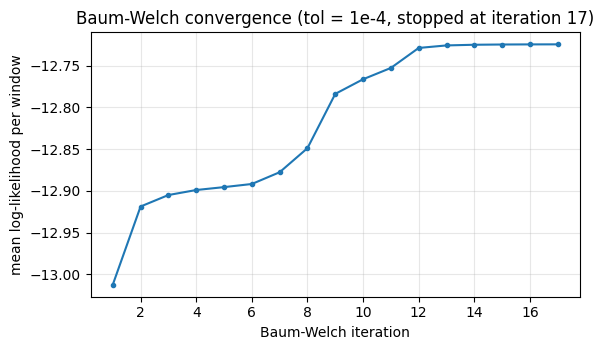

In [13]:
train_sessions = make_sessions(train_df)
X_tr = [s[0] for s in train_sessions]; z_tr = [s[1] for s in train_sessions]

# (a) supervised maximum-likelihood estimates from the labels
hmm_sup = GaussianHMM(n_states=K, var_floor=BEST_FLOOR).fit_supervised(X_tr, z_tr)

# (b) Baum-Welch refinement: uses only the observations, starts from (a), stops on a log-likelihood criterion
hmm_bw = hmm_sup.copy()
print("Baum-Welch training:")
history = hmm_bw.fit_baum_welch(X_tr, max_iter=200, tol=1e-4)
mono = bool(np.all(np.diff(history) > -1e-6))
print(f"Iterations: {len(history)} | converged: {hmm_bw.converged} | log-likelihood non-decreasing: {mono}")
print(f"Mean log-likelihood per window: {history[0]:.3f} -> {history[-1]:.3f}")

# The final model used for all results below = the one selected by cross-validation
hmm = hmm_bw if BEST_BW else hmm_sup
FINAL_NAME = "supervised + Baum-Welch" if BEST_BW else "supervised"
print(f"\nFinal model: {FINAL_NAME}")

print("\nInitial probabilities (pi):")
print(pd.DataFrame({"supervised": hmm_sup.pi, "Baum-Welch": hmm_bw.pi}, index=ACTIVITIES).round(3).to_string())
print("\nTransition matrix A of the final model:")
print(pd.DataFrame(hmm.A, index=ACTIVITIES, columns=ACTIVITIES).round(3))
RESULTS["baum_welch"] = dict(iterations=len(history), converged=bool(hmm_bw.converged), tol=1e-4,
                             start=float(history[0]), end=float(history[-1]), monotone=mono,
                             history=[float(h) for h in history], final=FINAL_NAME)

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(range(1, len(history) + 1), history, marker="o", ms=3)
ax.set_xlabel("Baum-Welch iteration"); ax.set_ylabel("mean log-likelihood per window")
ax.set_title(f"Baum-Welch convergence (tol = 1e-4, stopped at iteration {len(history)})")
ax.grid(alpha=.3); plt.tight_layout(); plt.savefig("figures/baum_welch_convergence.png", dpi=200, bbox_inches="tight"); plt.show()

### Transition matrix heatmap

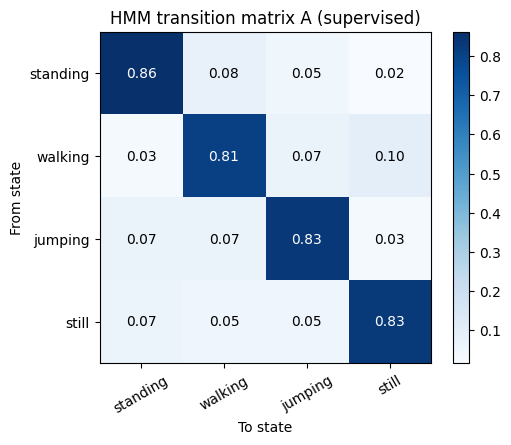

In [14]:
def heatmap(M, labels, title, fmt="{:.2f}", xlabel="To state", ylabel="From state", cmap="Blues", save=None, ax=None):
    own = ax is None
    if own: fig, ax = plt.subplots(figsize=(5.5, 4.5))
    im = ax.imshow(M, cmap=cmap)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=30)
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            ax.text(j, i, fmt.format(M[i, j]), ha="center", va="center",
                    color="white" if M[i, j] > M.max() * 0.6 else "black")
    ax.set_xlabel(xlabel); ax.set_ylabel(ylabel); ax.set_title(title)
    if own:
        fig.colorbar(im, ax=ax); plt.tight_layout()
        if save: fig.savefig(save, dpi=200, bbox_inches="tight")
        plt.show()

heatmap(hmm.A, ACTIVITIES, f"HMM transition matrix A ({FINAL_NAME})", save="figures/transition_matrix.png")
RESULTS["A_bw"] = np.round(hmm_bw.A, 4).tolist(); RESULTS["A_sup"] = np.round(hmm_sup.A, 4).tolist()
RESULTS["pi_bw"] = np.round(hmm_bw.pi, 4).tolist(); RESULTS["pi_sup"] = np.round(hmm_sup.pi, 4).tolist()

### Emission probabilities
Each state emits a 38-dimensional vector from its own diagonal Gaussian N(mu_k, var_k). The left panel shows the emission **means** (in z-score units) of the 12 features that differ most between states; the right panel shows the emission **densities** of the single most discriminative feature, i.e. the probability of observing a given feature value in each state.

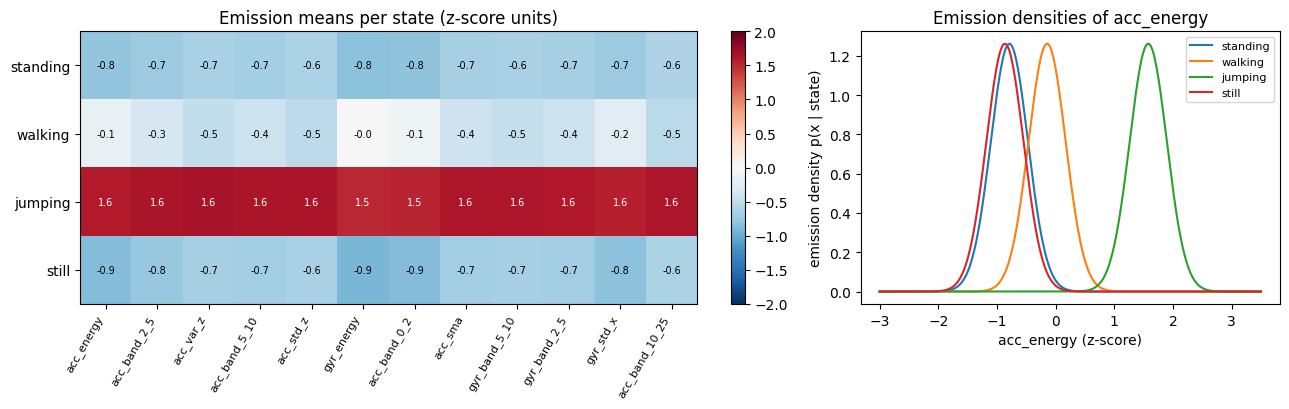

In [15]:
mu_e, var_e = hmm.mu, hmm.var
spread = mu_e.std(axis=0)
top = np.argsort(-spread)[:12]
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.6, 1]})
im = axes[0].imshow(mu_e[:, top], cmap="RdBu_r", vmin=-2, vmax=2, aspect="auto")
axes[0].set_yticks(range(len(ACTIVITIES))); axes[0].set_yticklabels(ACTIVITIES)
axes[0].set_xticks(range(len(top))); axes[0].set_xticklabels([FEATURES[i] for i in top], rotation=60, ha="right", fontsize=8)
for i in range(mu_e.shape[0]):
    for j, f in enumerate(top):
        axes[0].text(j, i, f"{mu_e[i, f]:.1f}", ha="center", va="center", fontsize=7,
                     color="white" if abs(mu_e[i, f]) > 1.2 else "black")
axes[0].set_title("Emission means per state (z-score units)")
fig.colorbar(im, ax=axes[0], fraction=0.03)
f0 = top[0]
xs = np.linspace(-3, 3.5, 400)
for k, a in enumerate(ACTIVITIES):
    s = np.sqrt(var_e[k, f0])
    axes[1].plot(xs, np.exp(-0.5 * ((xs - mu_e[k, f0]) / s) ** 2) / (s * np.sqrt(2 * np.pi)), label=a)
axes[1].set_xlabel(f"{FEATURES[f0]} (z-score)"); axes[1].set_ylabel("emission density p(x | state)")
axes[1].set_title(f"Emission densities of {FEATURES[f0]}"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.savefig("figures/emission_probabilities.png", dpi=200, bbox_inches="tight"); plt.show()
RESULTS["emission_top_features"] = [FEATURES[i] for i in top]

## 6. Evaluation on unseen data
The unseen recordings (`data/test/`, files 13-20 of every activity; recorded after the training files of the same activity, same day, same participant and phone) were **not** used for feature scaling, training or Baum-Welch. They are shuffled, concatenated into one test session, decoded with Viterbi and compared with the true labels window by window. The supervised-only model and a per-window classifier (no transitions) are evaluated as baselines.

In [16]:
def evaluate(model, df, rng):
    sessions = make_sessions(df, recs_per_session=10_000, rng=rng)   # one long session
    X, z = sessions[0]
    pred, _ = model.viterbi(X)
    return X, z, pred

K = len(ACTIVITIES)
def confusion(z, p, K):
    M = np.zeros((K, K), dtype=int)
    for a, b in zip(z, p):
        M[a, b] += 1
    return M

def metrics_table(M):
    N = M.sum(); rows = []
    overall = np.trace(M) / N
    for k, name in enumerate(ACTIVITIES):
        TP = M[k, k]; FN = M[k].sum() - TP
        FP = M[:, k].sum() - TP; TN = N - TP - FN - FP
        rows.append({"State (Activity)": name,
                     "Number of Samples": int(M[k].sum()),
                     "Sensitivity": TP / (TP + FN) if TP + FN else np.nan,
                     "Specificity": TN / (TN + FP) if TN + FP else np.nan,
                     "Accuracy (one-vs-rest)": (TP + TN) / N,
                     "Overall Accuracy": overall})
    return pd.DataFrame(rows).set_index("State (Activity)")

X_test, z_test, z_pred = evaluate(hmm, test_df, np.random.default_rng(SEED))           # final model
_, _, z_pred_sup = evaluate(hmm_sup, test_df, np.random.default_rng(SEED))
_, _, z_pred_bw  = evaluate(hmm_bw,  test_df, np.random.default_rng(SEED))
z_base = (hmm.log_emission(X_test) + np.log(hmm.pi)).argmax(axis=1)                    # no transition model

M_hmm, M_sup, M_bw, M_base = (confusion(z_test, p, K) for p in (z_pred, z_pred_sup, z_pred_bw, z_base))
acc = lambda M: np.trace(M) / M.sum()

print(f"=== Final model ({FINAL_NAME}) + Viterbi on unseen data ===")
tab_final = metrics_table(M_hmm)
display(tab_final.round(3))
print(f"\nOverall accuracy | final model: {acc(M_hmm):.3f} ({np.trace(M_hmm)}/{M_hmm.sum()})"
      f" | supervised only: {acc(M_sup):.3f} | supervised + Baum-Welch: {acc(M_bw):.3f}"
      f" | per-window Gaussian, no transitions: {acc(M_base):.3f}")
print(f"Forward log-likelihood of the unseen session: supervised {hmm_sup.forward_loglik(X_test):.1f} | Baum-Welch {hmm_bw.forward_loglik(X_test):.1f}")
RESULTS["eval"] = dict(final=FINAL_NAME, table=tab_final.reset_index().round(4).to_dict(orient="records"),
                       acc_final=float(acc(M_hmm)), acc_sup=float(acc(M_sup)), acc_bw=float(acc(M_bw)), acc_base=float(acc(M_base)),
                       correct=int(np.trace(M_hmm)), total=int(M_hmm.sum()),
                       M_final=M_hmm.tolist(), M_sup=M_sup.tolist(), M_bw=M_bw.tolist(), M_base=M_base.tolist(),
                       table_sup=metrics_table(M_sup).reset_index().round(4).to_dict(orient="records"),
                       table_bw=metrics_table(M_bw).reset_index().round(4).to_dict(orient="records"),
                       ll_test_sup=float(hmm_sup.forward_loglik(X_test)), ll_test_bw=float(hmm_bw.forward_loglik(X_test)))

=== Final model (supervised) + Viterbi on unseen data ===


,Number of Samples,Sensitivity,Specificity,Accuracy (one-vs-rest),Overall Accuracy
State (Activity),,,,,
standing,39,0.949,0.949,0.949,0.949
walking,49,1.000,1.000,1.000,0.949
jumping,47,1.000,1.000,1.000,0.949
still,42,0.833,0.985,0.949,0.949



Overall accuracy | final model: 0.949 (168/177) | supervised only: 0.949 | supervised + Baum-Welch: 0.972 | per-window Gaussian, no transitions: 0.904
Forward log-likelihood of the unseen session: supervised -2491.9 | Baum-Welch -2393.6


### Confusion matrix and decoded sequence

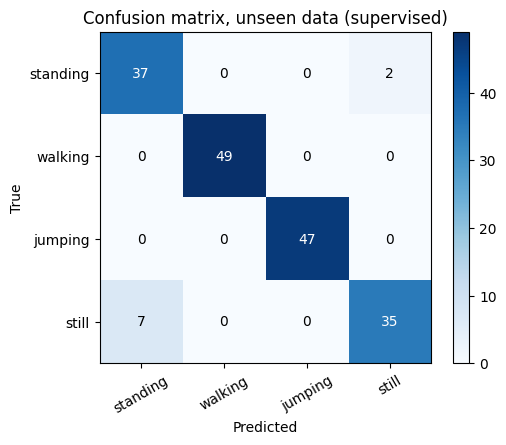

In [17]:
heatmap(M_hmm, ACTIVITIES, f"Confusion matrix, unseen data ({FINAL_NAME})", fmt="{:d}",
        xlabel="Predicted", ylabel="True", save="figures/confusion_matrix.png")

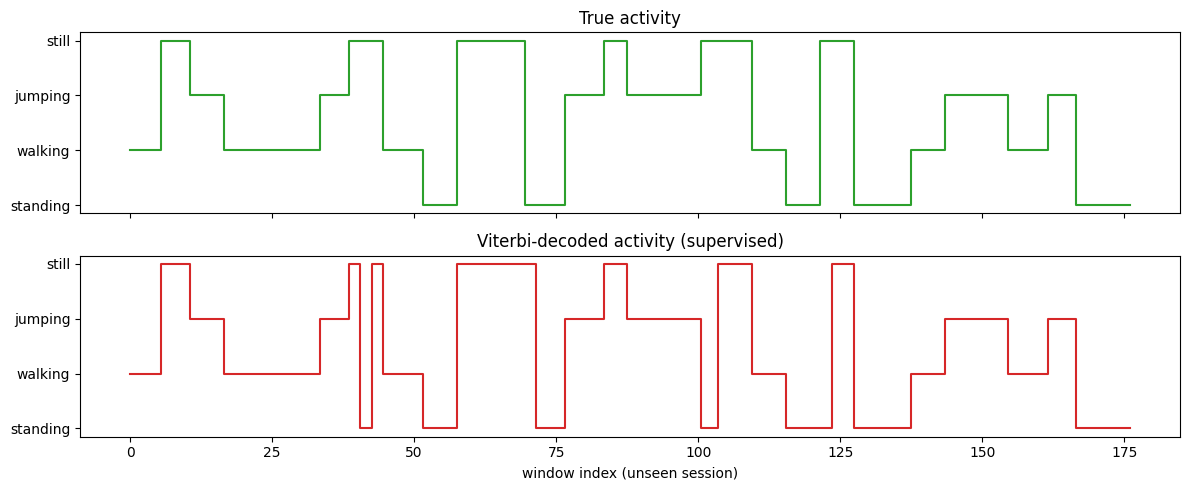

In [18]:
fig, axes = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
axes[0].step(range(len(z_test)), z_test, where="mid", color="tab:green")
axes[0].set_title("True activity")
axes[1].step(range(len(z_pred)), z_pred, where="mid", color="tab:red")
axes[1].set_title(f"Viterbi-decoded activity ({FINAL_NAME})")
for ax in axes:
    ax.set_yticks(range(K)); ax.set_yticklabels(ACTIVITIES)
axes[1].set_xlabel("window index (unseen session)")
plt.tight_layout(); plt.savefig("figures/decoded_sequence.png", dpi=200, bbox_inches="tight"); plt.show()

In [19]:
# Most common confusions on the unseen data
M = M_hmm.copy()
pairs = [(ACTIVITIES[i], ACTIVITIES[j], M[i, j]) for i in range(K) for j in range(K) if i != j and M[i, j] > 0]
pairs.sort(key=lambda p: -p[2])
print("Most common confusions (true -> predicted : windows):")
for a, b, n in pairs[:5] or [("none", "none", 0)]:
    print(f"  {a} -> {b} : {n}")
RESULTS["confusions"] = [(a, b, int(n)) for a, b, n in pairs[:5]]

# Average standardized feature values per activity (training data)
check = ["acc_std_z", "acc_sma", "acc_dom_freq", "acc_energy", "gyr_energy"]
print()
print(train_df.groupby("label")[check].mean().round(2))
RESULTS["feature_means"] = train_df.groupby("label")[check].mean().round(2).to_dict()

Most common confusions (true -> predicted : windows):
  still -> standing : 7
  standing -> still : 2

          acc_std_z  acc_sma  acc_dom_freq  acc_energy  gyr_energy
label                                                             
jumping        1.63     1.61         -0.04        1.58        1.50
standing      -0.63    -0.67         -0.23       -0.79       -0.82
still         -0.64    -0.69          0.94       -0.86       -0.91
walking       -0.52    -0.42         -0.51       -0.14       -0.01


## 7. Robustness and window-size sensitivity
### 7.1 Sensor noise and sampling rate
Noise proportional to each channel's standard deviation is added to the unseen signals, or the sampling rate is reduced by keeping every 2nd / 5th sample and interpolating back to the 50 Hz grid. Five independent noise draws are averaged so that a single lucky draw does not decide the result.

In [20]:
def eval_variant(transform):
    recs = [{**r, "signal": transform(r["signal"])} for r in test_recs]
    df = build_feature_table(recs)
    lg = log_transform(df)
    df[FEATURES] = (lg[FEATURES] - mu) / sd
    X, z, p = evaluate(hmm, df, np.random.default_rng(SEED))
    return (p == z).mean()

def noisy(k, seed):
    r_ = np.random.default_rng(seed)
    return lambda s: s + r_.normal(0, k * s.std(axis=0), s.shape)

def lower_rate(f):   # keep every f-th sample, then interpolate back to the common grid
    def tf(s):
        idx = np.arange(0, len(s), f)
        return np.column_stack([np.interp(np.arange(len(s)), idx, s[idx, c]) for c in range(s.shape[1])])
    return tf

rows = [("original (50 Hz)", eval_variant(lambda s: s), 0.0)]
for k in (0.25, 0.5, 1.0):
    a = [eval_variant(noisy(k, s)) for s in range(5)]
    rows.append((f"+ noise ({k:.0%} of signal std), mean of 5 draws", float(np.mean(a)), float(np.std(a))))
for f in (2, 5):
    rows.append((f"effective rate {FS // f} Hz (interpolated back to 50 Hz)", eval_variant(lower_rate(f)), 0.0))
rob = pd.DataFrame(rows, columns=["condition", "overall accuracy", "std over draws"]).round(3)
display(rob)
RESULTS["robustness"] = rob.to_dict(orient="records")

,condition,overall accuracy,std over draws
0,original (50 Hz),0.949,0.000
1,"+ noise (25% of signal std), mean of 5 draws",0.908,0.026
2,"+ noise (50% of signal std), mean of 5 draws",0.866,0.031
3,"+ noise (100% of signal std), mean of 5 draws",0.821,0.016
4,effective rate 25 Hz (interpolated back to 50 Hz),0.932,0.000
5,effective rate 10 Hz (interpolated back to 50 Hz),0.853,0.000


### 7.2 Window-size sensitivity
The 2 s window was chosen from the signal physics in Section 1.1, *not* tuned on the unseen set. As a sanity check the full pipeline (windowing, features, z-score, supervised HMM, Viterbi) is repeated with 1 s, 2 s and 3 s windows (50% overlap, same variance floor and training method as the final model). Accuracy is split into the two *periodic* activities (walking, jumping) and the two *static* ones (standing, still).

In [21]:
def window_experiment(win_s):
    global WIN_S
    old = WIN_S; WIN_S = win_s
    try:
        with contextlib.redirect_stdout(io.StringIO()):
            tr, te = load_folder(DATA_DIR), load_folder(TEST_DIR)
        trd, ted = build_feature_table(tr), build_feature_table(te)
        a, b = log_transform(trd), log_transform(ted)
        m_, s_ = a[FEATURES].mean(), a[FEATURES].std().replace(0, 1.0)
        trd[FEATURES], ted[FEATURES] = (a[FEATURES] - m_) / s_, (b[FEATURES] - m_) / s_
        sess = make_sessions(trd, rng=np.random.default_rng(SEED))
        h = GaussianHMM(K, var_floor=BEST_FLOOR).fit_supervised([s[0] for s in sess], [s[1] for s in sess])
        if BEST_BW:
            h.fit_baum_welch([s[0] for s in sess], max_iter=200, tol=1e-4, verbose=False)
        X, z, p = evaluate(h, ted, np.random.default_rng(SEED))
        per = lambda ks: float(np.mean(np.isin(z, ks) & (p == z)) / np.mean(np.isin(z, ks)))
        return dict(window_s=win_s, samples=int(round(win_s * FS)), fft_resolution_hz=1 / win_s,
                    train_windows=len(trd), unseen_windows=len(ted), accuracy=float((p == z).mean()),
                    walking_jumping_acc=per([1, 2]), standing_still_acc=per([0, 3]))
    finally:
        WIN_S = old

wtab = pd.DataFrame([window_experiment(w) for w in (1.0, 2.0, 3.0)]).round(3)
display(wtab.set_index("window_s"))
RESULTS["window_sensitivity"] = wtab.to_dict(orient="records")
assert WIN_S == 2.0

,samples,fft_resolution_hz,train_windows,unseen_windows,accuracy,walking_jumping_acc,standing_still_acc
window_s,,,,,,,
1.0,50,1.000,585,402,0.893,0.991,0.782
2.0,100,0.500,259,177,0.949,1.000,0.889
3.0,150,0.333,146,103,0.932,1.000,0.851


## 8. Analysis and reflection

**Unseen data and generalization.** The unseen set is 177 windows from 31 recordings (files 13-20 of each activity). They were recorded later than the training files of the same activity, on the same day, by the same participant with the same phone, so this tests generalization across *repetitions*, not across people, devices or placements. None of them was used for scaling, cross-validation, training or Baum-Welch. The final model (selected by training-set cross-validation: supervised estimates, variance floor 0.1) reaches **94.9%** (168/177 windows); decoding every window independently, without the transition model, reaches 90.4%, so the temporal model adds about 4.5 points. The Baum-Welch-refined model reaches 97.2% on the same data (and a higher likelihood), but it did *not* win the cross-validation on the training data (0.870 against 0.906 at the selected floor), so it is reported as a comparison and not swapped in after seeing the test result. The difference (4 windows) is within what a test set of this size can resolve. Within these limits the model generalizes well.

**Easiest and hardest activities.** Walking and jumping are the easiest: both are recognized with sensitivity and specificity of 1.00. Jumping has far more acceleration energy than any other activity (standardized acc_std_z of +1.63 against -0.52 to -0.64) and walking has its own rhythm (dominant frequency about 1.0 Hz against about 3.5 Hz for jumping). Standing versus still is the hardest pair: all 9 errors are between these two (7 still windows decoded as standing, 2 standing windows decoded as still; sensitivity 0.83 for still and 0.95 for standing). A phone held at waist level by a person standing still moves very little, so acceleration features are almost identical (acc_sma of -0.67 against -0.69 in z-score units). The gyroscope energy shows the larger gap (-0.82 against -0.91), because a phone resting on a surface hardly rotates at all. The Sensor Logger accelerometer has gravity removed (static means are about 0), so the *tilt* of the phone, which would clearly separate "held at the waist" from "lying flat", is invisible to the model.

**Transition probabilities.** The diagonal of A is strong (0.81-0.86) and the off-diagonal values are small but non-zero (0.015-0.096), so an activity usually continues and switching is allowed but unlikely, which is the right qualitative shape. The numbers themselves are an artefact of how the training sessions were built: each recording yields only about 5.5 windows and 8 shuffled recordings are joined, so a different activity follows after roughly 0.14 of the windows, i.e. a self-transition probability of about 0.86, matching the learned diagonal. In real life activities last minutes, so true self-transition probabilities would be much closer to 1, and the off-diagonals (for example jumping to still) would reflect habits. Learning them requires continuous recordings with real activity changes.

**Sensor noise and sampling rate.** The phone's native rate was 49.64 Hz with slightly irregular timestamps, so every channel was interpolated onto an exact 50 Hz grid. This keeps the FFT valid and the two sensors aligned. Adding Gaussian noise proportional to each channel's standard deviation lowers accuracy from 94.9% to 90.8% (25% noise), 86.6% (50%) and 82.1% (100%), averaged over 5 draws; the static states are expected to suffer most because their signal is small compared with the noise (this was not measured per activity). Reducing the effective rate to 25 Hz costs little (93.2%), while 10 Hz drops accuracy to 85.3%: with only a 5 Hz Nyquist limit the 5-10 Hz and 10-25 Hz band-energy features are removed and the dominant frequency of jumping is near the limit. 25 Hz was still adequate here, and 50 Hz leaves a safety margin.

**Window size.** The 2 s window gave the best accuracy (94.9%) against 89.3% for 1 s and 93.2% for 3 s. Walking and jumping stay at or near 100% for every window length; the window mostly affects the static pair (standing/still accuracy 78.2% at 1 s, 88.9% at 2 s, 85.1% at 3 s), where a 1 s window probably gives too few samples for stable variance and correlation estimates.

**Improvements.** (1) More data from several people, phones and phone positions, and recordings in different places, to test real generalization. (2) Continuous recordings with real transitions so that A and pi are meaningful. (3) Posture features: record the gravity vector or the raw accelerometer and add tilt angles, which should separate standing from still; plus autocorrelation, wavelet or cepstral features. (4) Fewer, better features (feature selection or PCA) and full-covariance or Gaussian-mixture emissions instead of 38 independent Gaussians per state. (5) Hidden semi-Markov (explicit duration) models, because activities last much longer than one window. (6) Additional sensors such as the magnetometer or barometer.

In [22]:
with open("results_summary.json", "w") as fh:
    json.dump(RESULTS, fh, indent=2, default=float)
print("saved results_summary.json and figures/:", sorted(os.listdir("figures")))

saved results_summary.json and figures/: ['baum_welch_convergence.png', 'confusion_matrix.png', 'decoded_sequence.png', 'emission_probabilities.png', 'raw_signals.png', 'spectra.png', 'transition_matrix.png']
